# Ablation of the selection procedure

This notebook measures AutoHybTS's **own procedure** (§30.5 of the specification): four ways of choosing the final model, with **the same search budget** and **the same external tests**.

| Procedure | What it does |
|---|---|
| `lowest_error` | the finalist with the lowest error on `V_select`, no thresholds |
| `incremental` | the guarded incremental chain (gain ≥ 1%, wins ≥ 60%, variability), all families |
| `incremental_simple` | the same chain, only structures with up to 2 models (standalone and additive hybrid) |
| `guarded_nested` | like `incremental`; if nested CV (with the same families) says the procedure does not beat "the best base of the inner selection", the best base is kept |

The series are synthetic and daily, with three levels (strata) of residual predictability: AR(0) (nothing to correct), AR(0.5) and AR(0.8). Each series keeps its last 14 points as the sealed external test. Besides the best base chosen on `V_select`, each row holds the external error of `naive` and `seasonal_naive` as simple references.

The budget limits only the **number of candidates** (no clock), so the run is reproducible on another machine. The cost of each procedure includes everything it runs: search, selection and, for `guarded_nested`, the inner searches of nested CV.

> The external test is **for reporting only**. Do not pick the "winning" procedure with it: that would repeat the very mistake the ablation wants to measure.

This notebook is heavy (tens of minutes) and is versioned **with its outputs**.

> **Note:** the stored outputs were produced with the previous rule (median gain ≥ 1%). The current default requires a gain ≥ 5% and uses 7 origins per layer when they fit (ADR-0008); re-running this notebook (≈1 h) updates the numbers.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

import autohybts
from autohybts.benchmarks import (
    PROCEDURES,
    ablation_protocol,
    ablation_report,
    ablation_uncertainty,
    run_ablation,
    synthetic_cases,
)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## Questions

1. **Losses:** is guarded selection (`incremental`, `guarded_nested`) worse than the best base in fewer cases than `lowest_error`?
2. **Useful gains:** when the residual is predictable (AR(0.8)), do the guarded procedures still choose the hybrid and beat the base?
3. **Complexity:** how much complexity (hybrids, fitted models) does each procedure accept when there is nothing to learn (AR(0))?
4. **Cost:** how much does each procedure cost, counting nested CV?

The answers hold only for these series, this horizon and this budget.

## 1. Configuration

In [2]:
N_SERIES = 12
SEEDS = (0, 1, 2)
BUDGET = "small"  # 50 candidates: the search no longer stops at the total limit

cases = list(synthetic_cases(N_SERIES))
protocol = ablation_protocol(cases, SEEDS, BUDGET)
print("budget:", protocol["budget"])
pd.DataFrame(protocol["series"])

budget: {'preset': 'small', 'guard': {'max_trials_total': 50, 'max_trials_per_family': 15, 'max_candidates_per_stage': 25, 'max_refinements': 2}}


,series_id,length,horizon,test_size,seasonal_period,stratum
0,syn0-phi0.0,400,14,14,7,phi=0.0
1,syn1-phi0.5,400,14,14,7,phi=0.5
2,syn2-phi0.8,400,14,14,7,phi=0.8
3,syn3-phi0.0,400,14,14,7,phi=0.0
4,syn4-phi0.5,400,14,14,7,phi=0.5
5,syn5-phi0.8,400,14,14,7,phi=0.8
6,syn6-phi0.0,400,14,14,7,phi=0.0
7,syn7-phi0.5,400,14,14,7,phi=0.5
8,syn8-phi0.8,400,14,14,7,phi=0.8
9,syn9-phi0.0,400,14,14,7,phi=0.0


## 2. Run

For each series and seed: one search with every family (used by `lowest_error`, `incremental` and `guarded_nested`), one restricted search (`incremental_simple`) and nested CV (`guarded_nested`). Each candidate is evaluated **only once** on the external test.

In [3]:
started = time.perf_counter()
table = run_ablation(cases, seeds=SEEDS, budget=BUDGET)
print(f"{len(table)} rows in {(time.perf_counter() - started) / 60:.1f} min")
print("search stops:", table["stop_reason"].value_counts().to_dict())
print(
    "prunes by limit:",
    table.drop_duplicates(["series_id", "seed", "search"])["pruned_by"].value_counts().to_dict(),
)
table[["series_id", "seed", "procedure", "champion", "test_score", "gain_vs_base"]].head(8)

144 rows in 55.5 min
search stops: {'budget_limited': 108, 'completed': 36}
prunes by limit: {'max_trials_per_family:6': 36, '': 36}


,series_id,seed,procedure,champion,test_score,gain_vs_base
0,syn0-phi0.0,0,lowest_error,stl(linear-linear),1.020015,0.06656
1,syn0-phi0.0,0,incremental,seasonal_naive,1.038440,0.04970
2,syn0-phi0.0,0,incremental_simple,seasonal_naive,1.038440,0.04970
3,syn0-phi0.0,0,guarded_nested,knn,1.092749,0.00000
4,syn0-phi0.0,1,lowest_error,stl(linear-linear),1.020015,0.06656
5,syn0-phi0.0,1,incremental,knn,1.092749,0.00000
6,syn0-phi0.0,1,incremental_simple,knn,1.092749,0.00000
7,syn0-phi0.0,1,guarded_nested,knn,1.092749,0.00000


## 3. Summary per procedure

* `median_gain_vs_base`: median gain on the test against the best standalone base on `V_select` (positive = better).
* `beats_base_share`, `ties_base_share`, `worse_than_base_share`: fractions of cases better than, equal to and worse than that base.
* `hybrid_share` and `mean_complexity`: fraction of hybrids chosen and mean number of models fitted in the structure.
* `mean_gap`: test error minus `V_select` error (positive = validation was optimistic).
* `mean_rank`: mean rank on the test among the 4 procedures (lower = better).
* `mean_seconds`, `candidates`, `units`: mean cost of the procedure (without the final refit or the reading of the test).
* `seed_std_of_median_gain`: how much the median gain varies across seeds.

In [4]:
report = ablation_report(table)
report.round(4)

,median_gain_vs_base,beats_base_share,ties_base_share,worse_than_base_share,hybrid_share,mean_complexity,mean_gap,mean_rank,coverage,mean_seconds,candidates,units,seed_std_of_median_gain
procedure,,,,,,,,,,,,,
lowest_error,0.0,0.4444,0.4722,0.0833,0.5278,1.6389,0.0242,2.2083,1.0,33.5194,41.0,96.0,0.0166
incremental,0.0,0.2778,0.6944,0.0278,0.1389,1.1667,0.0449,2.4306,1.0,33.5194,41.0,96.0,0.0000
incremental_simple,0.0,0.1944,0.7778,0.0278,0.0556,1.0556,0.0592,2.6944,1.0,4.7099,17.0,44.0,0.0000
guarded_nested,0.0,0.1389,0.8611,0.0000,0.1111,1.1389,0.0635,2.6667,1.0,87.6326,123.0,288.0,0.0000


### Uncertainty

The seeds of a series are not independent: each series' gain is summarized (median across seeds) and the 95% interval resamples **series**.

In [5]:
ablation_uncertainty(table).round(4)

,n_series,median_gain_vs_base,ci_low,ci_high,better_share,worse_share
procedure,,,,,,
lowest_error,12,0.0235,0.0,0.0791,0.5000,0.0833
incremental,12,0.0000,0.0,0.0000,0.1667,0.0000
incremental_simple,12,0.0000,0.0,0.0000,0.1667,0.0000
guarded_nested,12,0.0000,0.0,0.0000,0.0833,0.0000


## 4. By level of residual predictability

When the residual is white noise (AR(0)), a hybrid has nothing to learn: a good procedure should keep the base. With AR(0.8), there is something to correct.

First, each case as a point (ties with the base stay visible in grey); then, per stratum, the fraction of cases better than, equal to and worse than the base.

In [6]:
by_stratum = ablation_report(table, by="stratum")
columns = ["median_gain_vs_base", "beats_base_share", "worse_than_base_share", "hybrid_share"]
by_stratum[columns].round(3)

median_gain_vs_base  beats_base_share  worse_than_base_share  hybrid_share
stratum procedure                                                                                     
phi=0.0 lowest_error                      0.067             0.667                  0.250         0.917
        incremental                       0.000             0.333                  0.083         0.250
        incremental_simple                0.000             0.250                  0.083         0.167
        guarded_nested                    0.000             0.167                  0.000         0.167
phi=0.5 lowest_error                      0.000             0.250                  0.000         0.250
        incremental                       0.000             0.333                  0.000         0.083
        incremental_simple                0.000             0.250                  0.000         0.000
        guarded_nested                    0.000             0.083                  0.000         0.083
phi=0.8 lowest_error                      0.000             0.417                  0.000         0.417
        incremental                       0.000             0.167                  0.000         0.083
        incremental_simple                0.000             0.083                  0.000         0.000
        guarded_nested                    0.000             0.167                  0.000         0.083

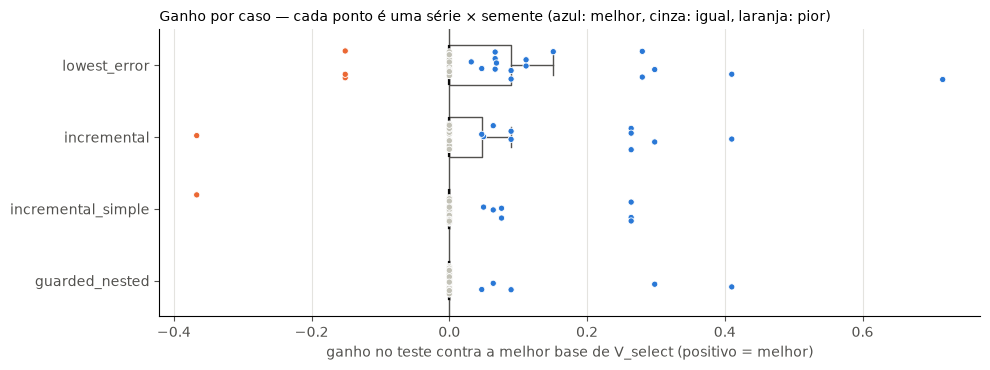

In [ ]:
# Visual: thin marks, recessive grid, one colour per meaning (better / tie / worse).
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BETTER, TIE, WORSE = "#2a78d6", "#c3c2b7", "#eb6834"
order = list(PROCEDURES)


def clean(ax, grid_axis="x"):
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)


def cases(ax, column, xlabel, signed=True):
    """Box per procedure with every case on top (zeros stay visible).

    ``signed`` colours points by better / tie / worse; otherwise they stay neutral.
    """
    rng = np.random.default_rng(0)
    for row, procedure in enumerate(order):
        values = table.loc[table["procedure"] == procedure, column].to_numpy()
        ax.boxplot(
            values,
            positions=[row],
            orientation="horizontal",
            widths=0.55,
            showfliers=False,
            medianprops={"color": INK, "linewidth": 1.6},
            boxprops={"color": MUTED},
            whiskerprops={"color": MUTED},
            capprops={"color": MUTED},
        )
        colors = np.where(values > 0, BETTER, np.where(values < 0, WORSE, TIE)) if signed else MUTED
        ax.scatter(
            values,
            row + rng.uniform(-0.2, 0.2, values.size),
            s=20,
            c=colors,
            edgecolors="white",
            linewidths=0.6,
            zorder=3,
        )
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_yticks(range(len(order)), order)
    ax.invert_yaxis()  # same top-to-bottom order as the stacked bars
    ax.set_xlabel(xlabel, color=MUTED)
    clean(ax)


fig, ax = plt.subplots(figsize=(10, 3.8))
cases(ax, "gain_vs_base", "gain on the test against the best base on V_select (positive = better)")
ax.set_title(
    "Gain per case — each point is a series × seed (blue: better, grey: equal, orange: worse)",
    loc="left",
    fontsize=10,
)
fig.tight_layout()

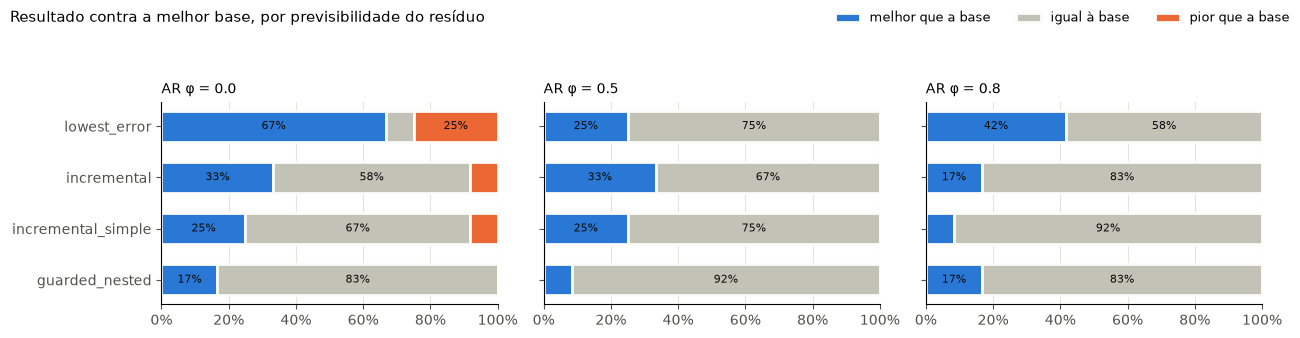

In [ ]:
labels = {"better": BETTER, "equal": TIE, "worse": WORSE}
outcome = np.select(
    [table["gain_vs_base"] > 0, table["gain_vs_base"] < 0], ["better", "worse"], "equal"
)
shares = (
    table.assign(result=outcome)
    .groupby(["stratum", "procedure"])["result"]
    .value_counts(normalize=True)
    .unstack(fill_value=0)
    .reindex(columns=list(labels), fill_value=0)
)
strata = sorted(table["stratum"].unique())
fig, axes = plt.subplots(1, len(strata), figsize=(13, 3.4), sharey=True)
for ax, stratum in zip(axes, strata, strict=True):
    part = shares.loc[stratum].reindex(order[::-1])
    left = np.zeros(len(part))
    for label, color in labels.items():
        values = part[label].to_numpy()
        ax.barh(
            part.index,
            values,
            left=left,
            color=color,
            height=0.6,
            edgecolor="#fcfcfb",
            linewidth=2,
            label=label,
        )
        for y, (value, start) in enumerate(zip(values, left, strict=True)):
            if value >= 0.12:
                ax.text(
                    start + value / 2,
                    y,
                    f"{value:.0%}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=INK,
                )
        left += values
    ax.set_title(stratum.replace("phi=", "AR φ = "), loc="left", fontsize=10)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    clean(ax)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    [f"{n} than the base" if n != "equal" else "equal to the base" for n in names],
    loc="upper right",
    ncol=3,
    frameon=False,
    fontsize=9,
)
fig.suptitle(
    "Result against the best base, by residual predictability", x=0.01, ha="left", fontsize=11
)
fig.tight_layout(rect=(0, 0, 1, 0.9))

## 5. Validation optimism

Gap = test error − `V_select` error. A procedure that picks by the lowest error tends to grab the candidate that got lucky in validation; the gap shows how much of that shows up on the test.

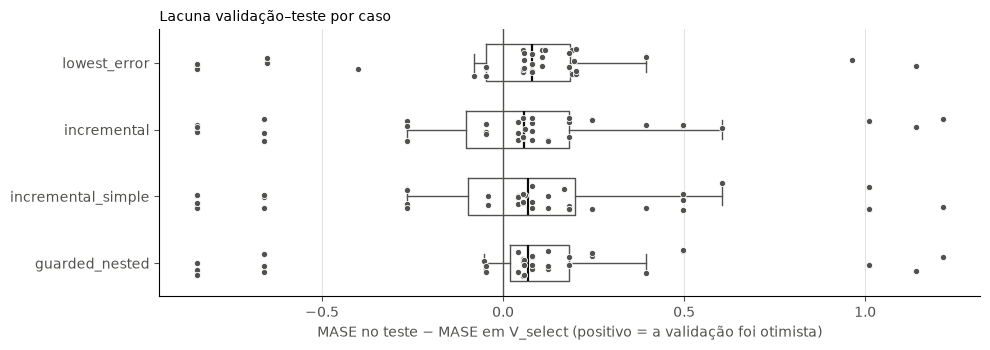

In [ ]:
fig, ax = plt.subplots(figsize=(10, 3.6))
cases(
    ax,
    "gap",
    "MASE on the test − MASE on V_select (positive = validation was optimistic)",
    signed=False,
)
ax.set_title("Validation–test gap per case", loc="left", fontsize=10)
fig.tight_layout()

## 6. Cost

Seconds per phase (mean per case) and work done. `lowest_error`, `incremental` and `guarded_nested` share the same search (column `search`): their search cost is the same work, not three measurements. `guarded_nested` adds the inner searches of nested CV (`nested_candidates`). `seconds_refit` (refit of the chosen model before the test) and `seconds_external` (reading of the test) are reported only, not a cost of the procedure.

In [9]:
cost_columns = [
    "seconds",
    "seconds_search",
    "seconds_selection",
    "seconds_nested",
    "seconds_refit",
    "seconds_external",
    "candidates",
    "search_candidates",
    "nested_candidates",
    "pruned_candidates",
    "units",
    "max_trials_total",
]
table.groupby("procedure")[cost_columns].mean().loc[order].round(2)

,seconds,seconds_search,seconds_selection,seconds_nested,seconds_refit,seconds_external,candidates,search_candidates,nested_candidates,pruned_candidates,units,max_trials_total
procedure,,,,,,,,,,,,
lowest_error,33.52,30.71,2.81,0.00,0.10,0.01,41.0,41.0,0.0,6.0,96.0,50.0
incremental,33.52,30.71,2.81,0.00,0.05,0.01,41.0,41.0,0.0,6.0,96.0,50.0
incremental_simple,4.71,4.13,0.58,0.00,0.02,0.01,17.0,17.0,0.0,0.0,44.0,50.0
guarded_nested,87.63,30.71,2.81,54.11,0.04,0.01,123.0,41.0,82.0,6.0,288.0,50.0


## 7. Chosen structures and simple references

In [10]:
chosen = table.groupby("procedure")["champion"].value_counts().unstack(fill_value=0).T
references = table.drop_duplicates(["series_id", "seed"])[
    ["best_base_test", "naive_test", "seasonal_naive_test"]
].median()
print("median test MASE of the references:", references.round(3).to_dict())
chosen

median test MASE of the references: {'best_base_test': 0.89, 'naive_test': 1.602, 'seasonal_naive_test': 1.025}


procedure,guarded_nested,incremental,incremental_simple,lowest_error
champion,,,,
"comb(linear,mlp)",0,0,0,1
knn,6,2,2,3
linear,21,22,24,9
"linear-comb(knn,linear)",0,0,0,1
"linear-comb(linear,knn)",0,0,0,1
linear-knn,0,0,0,3
linear-linear,0,0,2,2
ma(linear-knn),2,3,0,3
ma(linear-linear),0,0,0,1


## 8. Table and protocol

The full table (one row per series, seed and procedure) and the resolved protocol go to `artifacts/ablation/` (outside git). To repeat it from the command line: `python -m autohybts.benchmarks.ablation --dataset synthetic --series 12 --seeds 0 1 2 --budget small --out ablation.csv`.

In [11]:
import json
from pathlib import Path

folder = Path("artifacts") / "ablation"
folder.mkdir(parents=True, exist_ok=True)
table.to_csv(folder / "ablation.csv", index=False)
(folder / "ablation.protocol.json").write_text(
    json.dumps(protocol, indent=2, ensure_ascii=False, default=str), encoding="utf-8"
)
print(sorted(p.name for p in folder.iterdir()))

['ablation.csv', 'ablation.protocol.json']


## 9. Reading the results

In this run (12 series × 3 seeds, `small` budget, schema `ablation/2`, 55 min). No search stopped at the total limit; the searches with every family had 6 proposals pruned by the per-family limit, and the restricted search completed.

1. **Losses.** Against the best base on `V_select`, `lowest_error` is worse in 8% of cases; `incremental` and `incremental_simple` in 3%; `guarded_nested` in none.
2. **Useful gains.** `lowest_error` beats the base in 44% of cases (median per series of +2.4%, 95% CI from 0 to 7.9%). The guarded procedures beat it in 14–28% and have a median gain of 0. In the AR(0.8) stratum they choose a hybrid in only 0–8% of cases and beat the base in 8–17%, against 42% for `lowest_error`: the guard turns down most of the available gain.
3. **Complexity.** In the AR(0) stratum, `lowest_error` chooses a structure with a corrector or a decomposition in 92% of cases and beats the base in 67% of them: even without AR noise, the base does not capture all of the trend and seasonality, and structures such as `stl(linear-linear)` help. "Nothing to correct" holds for the noise, not for the shape of the signal. The guarded procedures stay at 17–25% hybrids in this stratum.
4. **Cost.** Per case: `incremental` 34 s and 41 candidates; `incremental_simple` 5 s and 17; `guarded_nested` 88 s and 123 (82 of them in nested CV).

The **validation–test gap** is positive for all of them and larger for the guarded ones. The simple references lag behind the best base: median MASE 0.89 (best base), 1.03 (`seasonal_naive`) and 1.60 (`naive`).

Compared with the `smoke` run (same series and seeds), the larger search brought `lowest_error` closer to a real gain (median per series from 0 to +2.4%) and reduced the hybrids of `incremental` (25% → 14%). Part of this may come from the budget alone: do not attribute the difference to a single change.

Limits: synthetic series, one horizon, 2 outer folds and one budget. The choice between accepting more gains (`lowest_error`) or avoiding losses (guarded) depends on which error is more expensive; notebook 11 measures the same trade-off on controls with a known answer. Do not pick the procedure by the external test.